In [ ]:
# 3F. Using the Sign Language MNIST dataset, select any one of the 24 alphabet classes
# (label Y-24) as an anomaly. Train an Autoencoder-Decoder model using the remaining
# 23 classes and detect the selected class as an anomaly based on reconstruction error.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import classification_report

In [2]:
train = pd.read_csv("/Users/aayushagarwal/Downloads/LP IV Updated Datasets/AutoEncoder/Sign Language MNIST/sign_mnist_train.csv")
test = pd.read_csv("/Users/aayushagarwal/Downloads/LP IV Updated Datasets/AutoEncoder/Sign Language MNIST/sign_mnist_test.csv")
print(train.shape , test.shape)

(27455, 785) (7172, 785)


In [3]:
anomaly_class = 0

x_train = train.drop("label" , axis=1).values / 255.0
y_train = train["label"].values
x_test = test.drop("label" , axis=1).values / 255.0
y_test = test["label"].values

In [4]:
# Train only on normal classes (anomaly class removed) :
x_train = x_train[y_train != anomaly_class]

# Test labels : 1 = anomaly , 0 = normal
y_test = np.where(y_test == anomaly_class , 1 , 0)
print(x_train.shape , x_test.shape)

(26329, 784) (7172, 784)


In [5]:
class Autoencoder(keras.Model):
    def __init__(self , output_units):
        super().__init__()

        self.encoder = keras.Sequential([
            keras.layers.Dense(128 , activation = "relu"),
            keras.layers.Dense(64 , activation = "relu"),
            keras.layers.Dense(32 , activation = "relu"),
        ])

        self.decoder = keras.Sequential([
            keras.layers.Dense(64 , activation = "relu"),
            keras.layers.Dense(128 , activation = "relu"),
            keras.layers.Dense(output_units , activation = "sigmoid"),
        ])

    def call(self , inputs):
        return self.decoder(self.encoder(inputs))

model = Autoencoder(x_train.shape[1])

In [6]:
model.compile(optimizer="adam" , loss="mse")

In [7]:
history = model.fit(x_train , x_train , epochs=20 , batch_size=128 , validation_split=0.1)

Epoch 1/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0271 - val_loss: 0.0198
Epoch 2/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0163 - val_loss: 0.0144
Epoch 3/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0135 - val_loss: 0.0129
Epoch 4/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0121 - val_loss: 0.0119
Epoch 5/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0109 - val_loss: 0.0106
Epoch 6/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0101 - val_loss: 0.0099
Epoch 7/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0095 - val_loss: 0.0105
Epoch 8/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0091 - val_loss: 0.0093
Epoch 9/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0088 - val_loss: 0.0088
Epoch 10/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0086 - val_loss: 0.0086
Epoch 11/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0084 - val_loss: 0.0085
Epoch 12/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

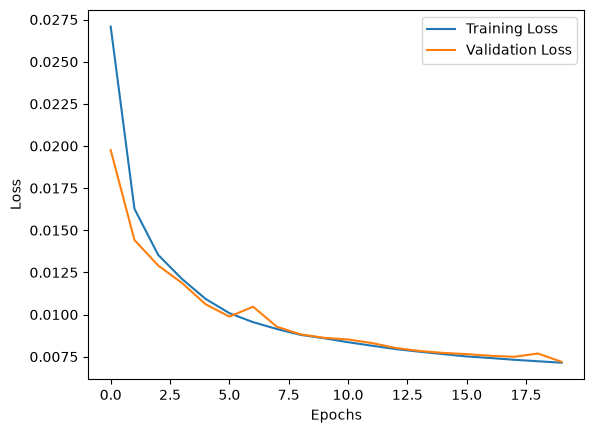

In [8]:
plt.plot(history.history["loss"] , label = "Training Loss")
plt.plot(history.history["val_loss"] , label = "Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

In [9]:
def get_errors(original , reconstructed):
    return np.mean(
        (original - reconstructed) ** 2 , axis = 1
    )

In [10]:
train_errors = get_errors(x_train , model.predict(x_train , verbose=0))
threshold = np.percentile(train_errors , 95)
print(threshold)

0.013031528094537653


In [11]:
test_errors = get_errors(x_test , model.predict(x_test , verbose = 0))
predictions = np.where(test_errors > threshold , 1 , 0)

In [12]:
print(classification_report(y_test , predictions , target_names=["Normal" , "Anomaly"]))

              precision    recall  f1-score   support

      Normal       0.96      0.92      0.94      6841
     Anomaly       0.07      0.12      0.09       331

    accuracy                           0.88      7172
   macro avg       0.51      0.52      0.51      7172
weighted avg       0.91      0.88      0.90      7172

